# Build the preprocessing feature tables

Extract six native-rate window features from complete EEG, EOG and EMG recordings and summarise them into twelve recording features.

In [12]:
import hashlib
import importlib.metadata
import json
import platform
from datetime import datetime, timezone
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from numpy.lib.stride_tricks import sliding_window_view
from scipy.linalg import eigh
from scipy.signal import fftconvolve, periodogram, welch
from tqdm import tqdm

plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 180, "font.size": 10, "axes.spines.top": False, "axes.spines.right": False, "legend.frameon": False})
pd.set_option("display.max_colwidth", 100)

## Configure the extraction

Set the channels, provisional technical quality rules and optional EEG SSA comparison before processing any recordings.

In [13]:
PROJECT_ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / "data" / "capslpdb" / "recordings.csv").is_file()), None)
if PROJECT_ROOT is None:
    raise FileNotFoundError("Run this notebook inside the project directory.")
DATA_DIR = PROJECT_ROOT / "data" / "capslpdb"
OUTPUT_DIR = PROJECT_ROOT / "outputs" / "preprocessing"
REPORT_DIR = OUTPUT_DIR / "reports"
FIGURE_DIR = OUTPUT_DIR / "figures"
REPORT_DIR.mkdir(parents=True, exist_ok=True)
FIGURE_DIR.mkdir(parents=True, exist_ok=True)
RECORD_IDS = None
MAX_WINDOWS_PER_RECORDING = None
EPOCH_SECONDS = 30
EEG_BANDS = {"delta": (0.5, 4.0), "theta": (4.0, 8.0), "alpha": (8.0, 13.0), "beta": (13.0, 30.0)}
EEG_POWER = "relative"
WELCH_SECONDS = 4
CENTER_EMG = True
CLIPPING_REJECT_FRACTION = 0.01
FLAT_STEP_REJECT_FRACTION = 0.995
AMPLITUDE_FLAG_UV = {"eeg": 1000.0, "eog": 1500.0, "emg": 5000.0}
INCLUDE_FLAGGED_WINDOWS = True
RUN_SSA = False
SSA_LAG_SECONDS = 0.5
SSA_MIN_BAND_FRACTION = 0.6
CHANNEL_CANDIDATES = {
    "eeg": [("C4-A1",), ("C4A1",), ("C4", "A1"), ("C3-A2",), ("C3A2",)],
    "eog": [("ROC-LOC",), ("LOC-ROC",), ("ROC", "LOC"), ("EOG-R", "EOG-L")],
    "emg": [("EMG1-EMG2",), ("EMG-EMG",), ("EMG1", "EMG2")],
}
CHANNEL_OVERRIDES = {
    "n4": {"eog": ("EOG dx", "EOG sin"), "emg": ("milo",)},
    "n6": {"eog": ("ROC-A2", "LOC-A1")},
    "n7": {"eog": ("ROC-A2", "LOC-A1")},
    "n8": {"emg": ("milo",)},
    "n9": {"eog": ("ROC-A2", "LOC-A1"), "emg": ("EMG",)},
    "n12": {"eog": ("ROC / A1", "LOC / A2"), "emg": (2, 3)},
}
FEATURE_COLUMNS = ["eeg_delta_power", "eeg_theta_power", "eeg_alpha_power", "eeg_beta_power", "eog_sd_uv", "emg_rms_uv"]
RECORDING_FEATURE_COLUMNS = [f"{feature}_{statistic}" for feature in FEATURE_COLUMNS for statistic in ("median", "p90")]
if any(low < 0 or high <= low for low, high in EEG_BANDS.values()):
    raise ValueError("EEG bands must have nonnegative, increasing bounds.")
if not 0 <= FLAT_STEP_REJECT_FRACTION <= 1 or any(value <= 0 for value in AMPLITUDE_FLAG_UV.values()):
    raise ValueError("Invalid flatness or amplitude thresholds.")
if EEG_POWER not in {"absolute", "relative"}:
    raise ValueError("EEG_POWER must be absolute or relative.")
if EPOCH_SECONDS <= 0 or WELCH_SECONDS > EPOCH_SECONDS:
    raise ValueError("Invalid window configuration.")
if not 0 <= CLIPPING_REJECT_FRACTION <= 1 or not 0 <= SSA_MIN_BAND_FRACTION <= 1:
    raise ValueError("Quality and SSA fractions must be between zero and one.")
if MAX_WINDOWS_PER_RECORDING is not None and MAX_WINDOWS_PER_RECORDING < 1:
    raise ValueError("MAX_WINDOWS_PER_RECORDING must be positive or None.")
if any(next_low != high for (_, high), (next_low, _) in zip(EEG_BANDS.values(), list(EEG_BANDS.values())[1:])):
    raise ValueError("The EEG bands must be contiguous.")
display(pd.DataFrame([
    {"Modality": "EEG", "Feature": name + " power", "Definition": f"{low:g}–{high:g} Hz; {EEG_POWER} power"}
    for name, (low, high) in EEG_BANDS.items()
] + [
    {"Modality": "EOG", "Feature": "Standard deviation", "Definition": "Population SD in µV"},
    {"Modality": "EMG", "Feature": "RMS", "Definition": "DC-centered RMS in µV" if CENTER_EMG else "Uncentered RMS in µV"},
]))

,Modality,Feature,Definition
0,EEG,delta power,0.5–4 Hz; relative power
1,EEG,theta power,4–8 Hz; relative power
2,EEG,alpha power,8–13 Hz; relative power
3,EEG,beta power,13–30 Hz; relative power
4,EOG,Standard deviation,Population SD in µV
5,EMG,RMS,DC-centered RMS in µV


## Read the dataset mapping

Keep recording identifiers and diagnosis labels as metadata rather than classifier inputs.

In [14]:
mapping = pd.read_csv(DATA_DIR / "recordings.csv", dtype=str)
required = {"record_id", "class_name", "original_group", "edf_path"}
if not required.issubset(mapping.columns):
    raise ValueError("Required mapping columns are missing.")
if mapping[list(required)].isna().any().any() or not mapping["record_id"].str.fullmatch(r"[a-z]+[0-9]+").all() or mapping["record_id"].duplicated().any():
    raise ValueError("The recordings mapping is incomplete or contains duplicate identifiers.")
if not mapping["class_name"].isin(["healthy", "rbd", "other"]).all():
    raise ValueError("Unexpected class labels.")
if RECORD_IDS is not None:
    missing_ids = set(RECORD_IDS) - set(mapping["record_id"])
    if missing_ids:
        raise ValueError(f"Unknown recording identifiers: {sorted(missing_ids)}")
    mapping = mapping[mapping["record_id"].isin(RECORD_IDS)].copy()
if mapping.empty:
    raise ValueError("No recordings were selected.")
mapping = mapping.sort_values("record_id").reset_index(drop=True)

def recording_path(relative_path):
    path = (DATA_DIR / relative_path).resolve()
    if not path.is_relative_to(DATA_DIR.resolve()):
        raise ValueError("The recording path leaves the dataset directory.")
    return path

display(mapping.groupby("class_name").size().rename("recordings").to_frame())

,recordings
class_name,
healthy,16
other,70
rbd,22


## Read EDF signals at their native rates

Load the selected channels for one complete night into RAM at their native rates before analysing its 30-second windows.

In [15]:
class NativeEDF:
    def __init__(self, path):
        self.path = Path(path)
        with self.path.open("rb") as stream:
            fixed = stream.read(256)
            if len(fixed) != 256 or fixed[:8].strip() != b"0":
                raise ValueError("Only standard 16-bit EDF files are supported.")
            if b"EDF+D" in fixed[192:236]:
                raise ValueError("Discontinuous EDF requires explicit time-gap handling.")
            self.header_bytes = int(fixed[184:192])
            self.record_count = int(fixed[236:244])
            self.record_seconds = float(fixed[244:252])
            self.channel_count = int(fixed[252:256])
            header = stream.read(self.channel_count * 256)
        if len(header) != self.channel_count * 256 or self.record_seconds <= 0:
            raise ValueError("Invalid EDF signal headers or record duration.")
        if self.header_bytes < 256 + self.channel_count * 256:
            raise ValueError("Invalid EDF header length.")
        def fields(offset, width):
            return [header[self.channel_count * offset + i * width:self.channel_count * offset + (i + 1) * width].decode("latin-1").strip() for i in range(self.channel_count)]
        self.labels = fields(0, 16)
        self.units = fields(96, 8)
        self.physical_min = np.array(fields(104, 8), dtype=float)
        self.physical_max = np.array(fields(112, 8), dtype=float)
        self.digital_min = np.array(fields(120, 8), dtype=int)
        self.digital_max = np.array(fields(128, 8), dtype=int)
        self.prefilters = fields(136, 80)
        self.samples_per_record = np.array(fields(216, 8), dtype=int)
        if np.any(self.samples_per_record <= 0):
            raise ValueError("EDF contains a channel without samples.")
        self.record_width = int(self.samples_per_record.sum())
        self.offsets = np.r_[0, np.cumsum(self.samples_per_record[:-1])]
        payload = self.path.stat().st_size - self.header_bytes
        bytes_per_record = self.record_width * 2
        if self.record_count == -1 and payload % bytes_per_record == 0:
            self.record_count = payload // bytes_per_record
        if self.record_count <= 0 or payload != self.record_count * bytes_per_record:
            raise ValueError("EDF length disagrees with its header; check for an incomplete file.")
        self.duration = self.record_count * self.record_seconds
        self._data = None

    def open(self):
        if self._data is None:
            self._data = np.memmap(self.path, dtype="<i2", mode="r", offset=self.header_bytes, shape=(self.record_count, self.record_width))
        return self

    def close(self):
        if self._data is not None:
            self._data._mmap.close()
            self._data = None

    def __enter__(self):
        return self.open()

    def __exit__(self, *args):
        self.close()

    def sfreq(self, index):
        return float(self.samples_per_record[index] / self.record_seconds)

    def read(self, index, start, stop):
        if self._data is None:
            raise RuntimeError("Open the EDF reader first.")
        per_record = int(self.samples_per_record[index])
        if start < 0 or stop <= start or stop > self.record_count * per_record:
            raise ValueError("Requested samples are outside the recording.")
        first, last = start // per_record, (stop - 1) // per_record + 1
        offset = int(self.offsets[index])
        digital = np.array(self._data[first:last, offset:offset + per_record], dtype=np.int32).reshape(-1)
        digital = digital[start - first * per_record:stop - first * per_record]
        span = self.digital_max[index] - self.digital_min[index]
        if span == 0 or self.physical_max[index] == self.physical_min[index]:
            raise ValueError("Invalid channel calibration.")
        unit = self.units[index].lower().replace("µ", "u").replace("μ", "u")
        factor = {"uv": 1.0, "mv": 1000.0, "v": 1e6}.get(unit)
        if factor is None:
            raise ValueError(f"Unsupported voltage unit for {self.labels[index]}: {self.units[index]}")
        values = (digital.astype(float) - self.digital_min[index]) * (self.physical_max[index] - self.physical_min[index]) / span + self.physical_min[index]
        channel = self._data[:, offset:offset + per_record]
        clipped = (digital <= channel.min()) | (digital >= channel.max())
        return values * factor, clipped

## Resolve and audit the channel montage

Select documented channel combinations and export unresolved or alternative montages for review before interpreting class comparisons.

In [16]:
def channel_key(label):
    return "".join(character for character in label.upper() if character.isalnum())

def resolve_channel(edf, record_id, modality):
    override = CHANNEL_OVERRIDES.get(record_id, {}).get(modality)
    if isinstance(override, str):
        raise ValueError("Channel overrides must be tuples of labels or EDF header indices.")
    candidates = [tuple(override)] if override is not None else CHANNEL_CANDIDATES[modality]
    for candidate in candidates:
        indices = []
        for label in candidate:
            matches = [label] if isinstance(label, int) and 0 <= label < edf.channel_count else ([] if isinstance(label, int) else [i for i, actual in enumerate(edf.labels) if channel_key(actual) == channel_key(label)])
            if len(matches) != 1:
                break
            indices.append(matches[0])
        if len(indices) != len(candidate):
            continue
        if len(indices) not in {1, 2} or len(set(indices)) != len(indices):
            raise ValueError("A montage must contain one channel or two distinct channels.")
        rates = [edf.sfreq(i) for i in indices]
        if not np.allclose(rates, rates[0]):
            raise ValueError("Bipolar derivation requires equal native sample rates.")
        if not np.isclose(EPOCH_SECONDS * rates[0], round(EPOCH_SECONDS * rates[0])):
            raise ValueError("The epoch duration must contain an integer number of native samples.")
        for i in indices:
            unit = edf.units[i].lower().replace("µ", "u").replace("μ", "u")
            if unit not in {"uv", "mv", "v"}:
                raise ValueError(f"Non-voltage channel selected: {edf.labels[i]}")
        if modality == "eeg" and rates[0] / 2 < max(high for low, high in EEG_BANDS.values()):
            raise ValueError("The EEG sampling rate cannot represent the configured bands.")
        actual_labels = [edf.labels[i] for i in indices]
        primary = tuple(channel_key(s) for s in CHANNEL_CANDIDATES[modality][0])
        alternate = tuple(channel_key(s) for s in actual_labels) != primary
        return {"indices": indices, "labels": actual_labels, "sfreq": rates[0], "derived": len(indices) == 2, "alternate": alternate}
    return None

headers = {}
plans = {}
inventory_rows = []
for record in tqdm(mapping.to_dict("records"), desc="Inspect EDF headers", unit="record"):
    record_id = record["record_id"]
    row = {"record_id": record_id, "class_name": record["class_name"], "original_group": record["original_group"], "edf_path": record["edf_path"]}
    try:
        edf = NativeEDF(recording_path(record["edf_path"]))
        plan = {modality: resolve_channel(edf, record_id, modality) for modality in CHANNEL_CANDIDATES}
        missing = [modality for modality, selection in plan.items() if selection is None]
        row.update({"status": "review_channels" if missing else "ready", "reason": "Missing unambiguous montage for " + ", ".join(missing) if missing else "", "duration_seconds": edf.duration, "all_channels": " | ".join(f"{i}: {label}" for i, label in enumerate(edf.labels))})
        for modality, selection in plan.items():
            row[f"{modality}_channels"] = " | ".join(selection["labels"]) if selection else ""
            row[f"{modality}_sfreq_hz"] = selection["sfreq"] if selection else np.nan
            row[f"{modality}_prefilter"] = " | ".join(edf.prefilters[i] for i in selection["indices"]) if selection else ""
        row["alternate_montage"] = any(selection and selection["alternate"] for selection in plan.values())
        headers[record_id] = edf
        if not missing:
            plans[record_id] = plan
    except (OSError, ValueError, OverflowError) as exc:
        row.update({"status": "invalid_recording", "reason": str(exc)})
    inventory_rows.append(row)
inventory = pd.DataFrame(inventory_rows)
inventory.to_csv(REPORT_DIR / "channel_inventory.csv", index=False)
display(pd.crosstab(inventory["class_name"], inventory["status"]))
display(inventory.loc[inventory["status"].ne("ready"), ["record_id", "class_name", "reason", "all_channels"]])
if not plans:
    raise ValueError("No recordings have a complete valid channel mapping.")

Inspect EDF headers: 100%|██████████| 108/108 [00:00<00:00, 1647.00record/s]


status,invalid_recording,ready,review_channels
class_name,,,
healthy,3,12,1
other,1,69,0
rbd,0,22,0


,record_id,class_name,reason,all_channels
0,brux1,other,EDF length disagrees with its header; check for an incomplete file.,NaN
15,n13,healthy,Non-voltage channel selected: C4A1,NaN
16,n14,healthy,Non-voltage channel selected: C4A1,NaN
17,n15,healthy,Non-voltage channel selected: C4A1,NaN
18,n16,healthy,"Missing unambiguous montage for eog, emg",0: Fp2-F4 | 1: F4-C4 | 2: C4-P4 | 3: P4-O2 | 4: C4-A1


## Define technical window quality checks

Reject non-finite, flat or substantially clipped windows while retaining high-amplitude warnings according to the configured policy.

In [17]:
def read_montage(edf, selection, start=0, stop=None):
    combined, clipped_combined = None, None
    for index in selection["indices"]:
        end = edf.record_count * int(edf.samples_per_record[index]) if stop is None else stop
        values, clipped = edf.read(index, start, end)
        combined = values if combined is None else combined - values
        clipped_combined = clipped if clipped_combined is None else clipped_combined | clipped
    return combined, clipped_combined

def assess_window(values, clipped, modality):
    reject, flags = [], []
    if not np.isfinite(values).all():
        return {"reject": [f"{modality}_nonfinite"], "flags": [], "ptp_uv": np.nan, "clip_fraction": np.nan}
    peak_to_peak = float(np.ptp(values))
    flat_fraction = float(np.mean(np.diff(values) == 0))
    clip_fraction = float(np.mean(clipped))
    if peak_to_peak == 0 or flat_fraction >= FLAT_STEP_REJECT_FRACTION:
        reject.append(f"{modality}_flat")
    if clip_fraction > 0:
        (reject if clip_fraction >= CLIPPING_REJECT_FRACTION else flags).append(f"{modality}_clipped")
    if peak_to_peak > AMPLITUDE_FLAG_UV[modality]:
        flags.append(f"{modality}_high_amplitude")
    return {"reject": reject, "flags": flags, "ptp_uv": peak_to_peak, "clip_fraction": clip_fraction}

## Define the optional EEG SSA comparison

Group components by their eigenvector spectra and reconstruct a candidate EEG representation without claiming automatic artifact removal.

In [18]:
def ssa_eeg(values, sfreq):
    centered = np.asarray(values, dtype=float) - np.mean(values)
    lag = round(SSA_LAG_SECONDS * sfreq)
    if not 2 <= lag <= len(centered) // 2:
        raise ValueError("SSA lag must be between two samples and half the epoch length.")
    trajectory = np.ascontiguousarray(sliding_window_view(centered, lag).T)
    columns = trajectory.shape[1]
    eigenvalues, vectors = eigh(trajectory @ trajectory.T / columns, check_finite=False)
    eigenvalues, vectors = np.maximum(eigenvalues[::-1], 0), vectors[:, ::-1]
    frequencies, power = periodogram(vectors, fs=sfreq, window="boxcar", detrend=False, axis=0)
    ranges = [(0.0, next(iter(EEG_BANDS.values()))[0]), *EEG_BANDS.values(), (max(high for low, high in EEG_BANDS.values()), np.inf)]
    contributions = np.array([power[(frequencies >= low) & (frequencies < high)].sum(axis=0) for low, high in ranges])
    contributions /= np.maximum(power.sum(axis=0), np.finfo(float).tiny)
    assignment = np.argmax(contributions, axis=0)
    counts = np.convolve(np.ones(lag), np.ones(columns))
    groups = {}
    selected_counts = {}
    for group_number, band in enumerate(EEG_BANDS, start=1):
        selected = np.flatnonzero((assignment == group_number) & (contributions[group_number] >= SSA_MIN_BAND_FRACTION) & (eigenvalues > eigenvalues.max() * 1e-12))
        selected_counts[band] = int(len(selected))
        reconstructed = np.zeros(len(centered))
        if len(selected):
            scores = vectors[:, selected].T @ trajectory
            for row, index in enumerate(selected):
                reconstructed += fftconvolve(vectors[:, index], scores[row], mode="full") / counts
        groups[band] = reconstructed
    if not any(selected_counts.values()):
        raise ValueError("SSA retained no components under the configured frequency rule.")
    return np.sum(list(groups.values()), axis=0), groups, selected_counts

## Define the six numerical features

Integrate Welch power over fixed EEG bands and compute EOG SD and EMG RMS from their native samples.

In [19]:
def band_integral(frequencies, power, low, high):
    inside = (frequencies > low) & (frequencies < high)
    grid = np.r_[low, frequencies[inside], high]
    selected_power = np.r_[np.interp(low, frequencies, power), power[inside], np.interp(high, frequencies, power)]
    return float(np.trapezoid(selected_power, grid))

def eeg_features(values, sfreq):
    segment = min(len(values), round(WELCH_SECONDS * sfreq))
    frequencies, power = welch(values, fs=sfreq, window="hann", nperseg=segment, noverlap=segment // 2, detrend="constant", scaling="density")
    band_power = {f"eeg_{name}_power": band_integral(frequencies, power, low, high) for name, (low, high) in EEG_BANDS.items()}
    total = sum(band_power.values())
    if total <= 0 or not np.isfinite(total):
        raise ValueError("EEG band power is not positive and finite.")
    if EEG_POWER == "relative":
        band_power = {name: value / total for name, value in band_power.items()}
    return band_power

def extract_features(signals, rates, eeg_override=None):
    eeg = signals["eeg"] if eeg_override is None else eeg_override
    emg = signals["emg"] - np.mean(signals["emg"]) if CENTER_EMG else signals["emg"]
    features = {**eeg_features(eeg, rates["eeg"]), "eog_sd_uv": float(np.std(signals["eog"], ddof=0)), "emg_rms_uv": float(np.sqrt(np.mean(emg ** 2)))}
    if not np.isfinite(list(features.values())).all():
        raise ValueError("Feature extraction produced non-finite values.")
    return features

## Load one complete recording and process its windows

Keep the selected EEG, EOG and EMG signals in RAM for one night and release them after its feature rows are returned.

In [20]:
def process_record(record, max_windows=None, use_ssa=None):
    record_id = record["record_id"]
    edf = headers[record_id]
    plan = plans[record_id]
    use_ssa = RUN_SSA if use_ssa is None else use_ssa
    full_windows = int(np.floor(edf.duration / EPOCH_SECONDS))
    count = min(full_windows, max_windows) if max_windows is not None else full_windows
    if count == 0:
        raise ValueError("Recording contains no complete epoch.")
    variants = {"baseline": []}
    if use_ssa:
        variants["ssa"] = []
    rates = {modality: selection["sfreq"] for modality, selection in plan.items()}
    with edf:
        loaded = {modality: read_montage(edf, selection) for modality, selection in plan.items()}
    loaded_megabytes = sum(values.nbytes + clipped.nbytes for values, clipped in loaded.values()) / 1024 ** 2
    samples_per_epoch = {modality: round(EPOCH_SECONDS * rates[modality]) for modality in plan}
    for index in range(count):
        signals = {modality: loaded[modality][0][index * samples:(index + 1) * samples] for modality, samples in samples_per_epoch.items()}
        clipping = {modality: loaded[modality][1][index * samples:(index + 1) * samples] for modality, samples in samples_per_epoch.items()}
        quality = {modality: assess_window(signals[modality], clipping[modality], modality) for modality in plan}
        rejections = [reason for item in quality.values() for reason in item["reject"]]
        flags = [reason for item in quality.values() for reason in item["flags"]]
        accepted = not rejections and (INCLUDE_FLAGGED_WINDOWS or not flags)
        base = {
            "record_id": record_id, "class_name": record["class_name"], "original_group": record["original_group"],
            "window_index": index, "start_seconds": index * EPOCH_SECONDS, "duration_seconds": EPOCH_SECONDS,
            "accepted": accepted, "quality_status": "exclude" if not accepted else ("flag" if flags else "keep"),
            "quality_reasons": ";".join(rejections + flags),
            "alternate_montage": any(selection["alternate"] for selection in plan.values()),
        }
        for modality in plan:
            base[f"{modality}_sfreq_hz"] = rates[modality]
            base[f"{modality}_channels"] = " minus ".join(plan[modality]["labels"])
            base[f"{modality}_ptp_uv"] = quality[modality]["ptp_uv"]
            base[f"{modality}_clipping_fraction"] = quality[modality]["clip_fraction"]
        for variant in variants:
            result = {**base, **dict.fromkeys(FEATURE_COLUMNS, np.nan)}
            if accepted:
                try:
                    if variant == "ssa":
                        reconstructed, _, component_counts = ssa_eeg(signals["eeg"], rates["eeg"])
                        result.update(extract_features(signals, rates, eeg_override=reconstructed))
                        result.update({f"ssa_{band}_components": n for band, n in component_counts.items()})
                    else:
                        result.update(extract_features(signals, rates))
                except (ValueError, np.linalg.LinAlgError, FloatingPointError) as exc:
                    result.update({"accepted": False, "quality_status": "exclude", "quality_reasons": ";".join(filter(None, [base["quality_reasons"], f"{variant}_feature_error: {exc}"]))})
            variants[variant].append(result)
    info = {"record_id": record_id, "duration_seconds": edf.duration, "loaded_megabytes": loaded_megabytes, "complete_windows": full_windows, "processed_windows": count, "trailing_seconds": edf.duration - full_windows * EPOCH_SECONDS, "limited_run": count < full_windows}
    return {name: pd.DataFrame(rows) for name, rows in variants.items()}, info

## Preview one real window

Inspect the chosen native-rate signals and the EEG spectrum before starting the full extraction.

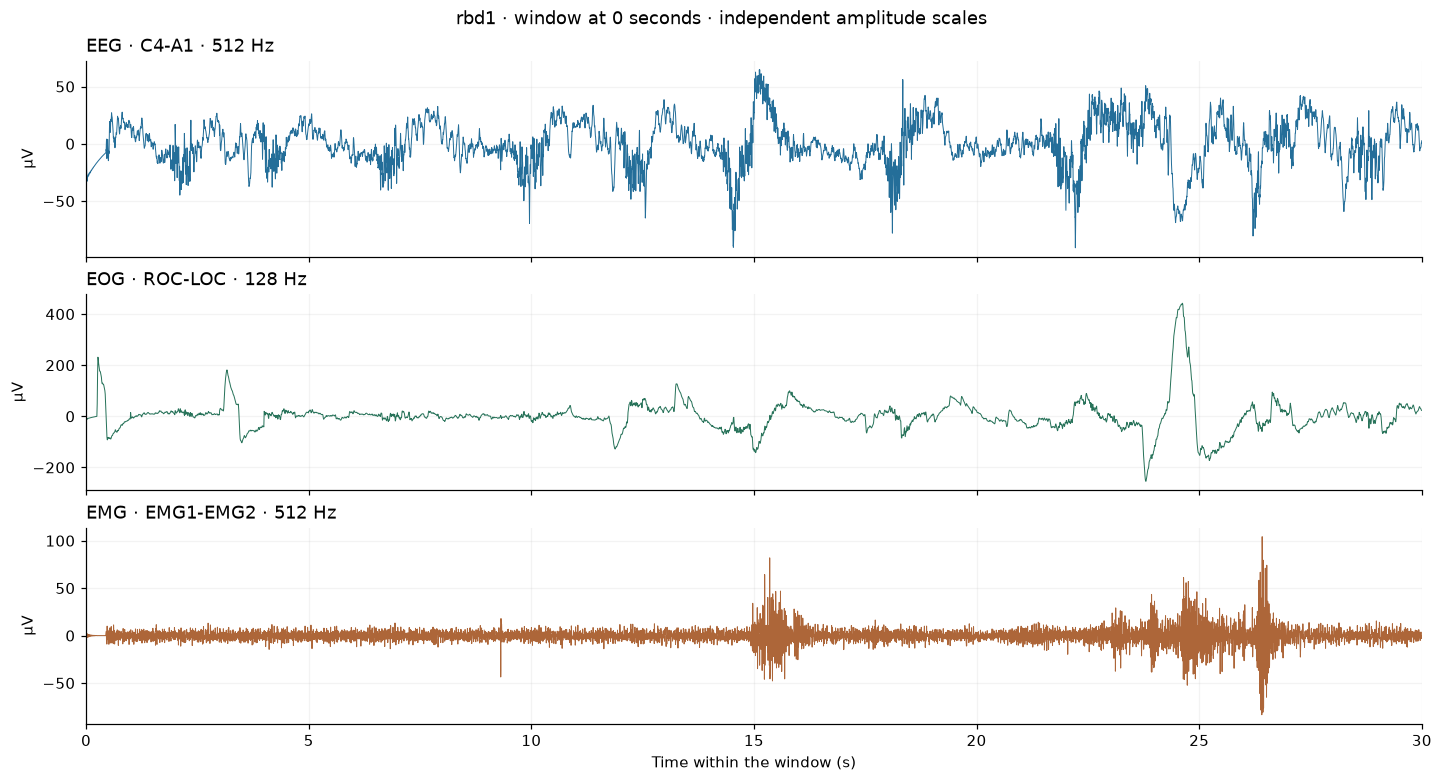

,reject,flags,ptp_uv,clip_fraction
eeg,[],[],155.433455,0.0
eog,[],[],696.69083,0.0
emg,[],[],187.637275,0.0


,eeg_delta_power,eeg_theta_power,eeg_alpha_power,eeg_beta_power,eog_sd_uv,emg_rms_uv
0,0.769825,0.113538,0.037531,0.079107,63.006713,7.535837


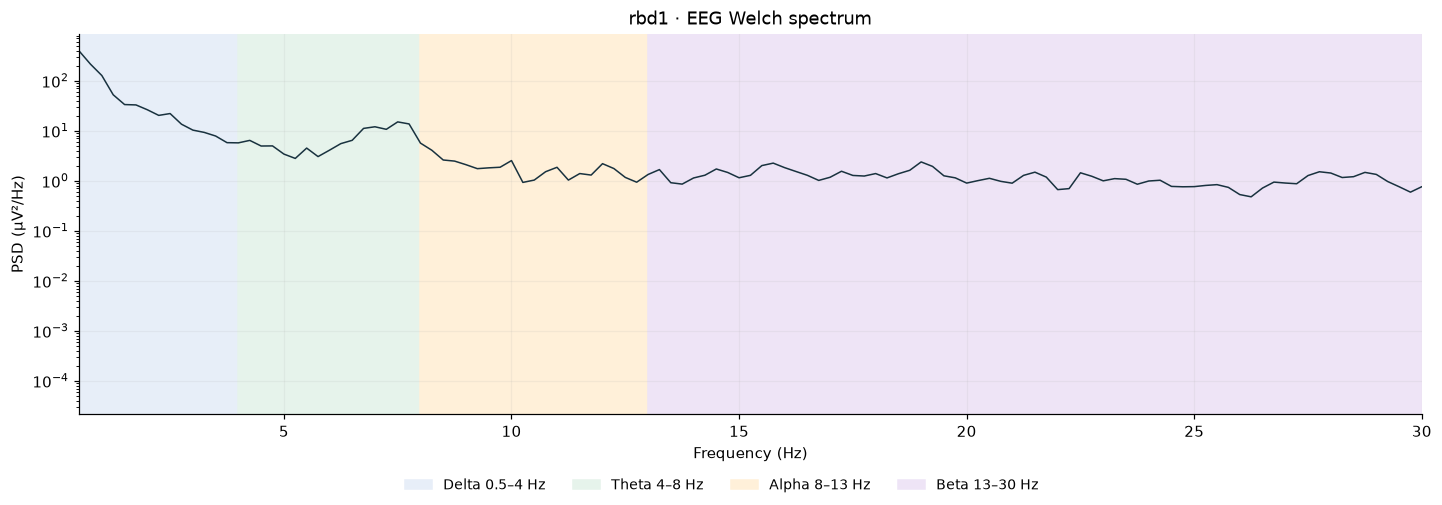

In [21]:
preview_id = "rbd1" if "rbd1" in plans else next(iter(plans))
preview_edf = headers[preview_id]
preview_plan = plans[preview_id]
preview_rates = {modality: selection["sfreq"] for modality, selection in preview_plan.items()}
preview_signals = None
with preview_edf:
    for preview_index in range(min(10, int(preview_edf.duration // EPOCH_SECONDS))):
        preview_blocks = {modality: read_montage(preview_edf, selection, preview_index * round(EPOCH_SECONDS * selection["sfreq"]), (preview_index + 1) * round(EPOCH_SECONDS * selection["sfreq"])) for modality, selection in preview_plan.items()}
        preview_signals = {modality: block[0] for modality, block in preview_blocks.items()}
        preview_qc = {modality: assess_window(preview_signals[modality], preview_blocks[modality][1], modality) for modality in preview_plan}
        if not any(item["reject"] for item in preview_qc.values()):
            break
if preview_signals is None:
    raise ValueError("No complete preview window exists.")
fig, axes = plt.subplots(3, 1, figsize=(13, 7), sharex=True, layout="constrained")
for ax, (modality, values), color in zip(axes, preview_signals.items(), ["#246e99", "#28735a", "#ad6639"]):
    time = np.arange(len(values)) / preview_rates[modality]
    ax.plot(time, values, color=color, linewidth=0.65)
    ax.set_title(f"{modality.upper()} · {' minus '.join(preview_plan[modality]['labels'])} · {preview_rates[modality]:g} Hz", loc="left")
    ax.set_ylabel("µV")
    ax.grid(alpha=0.15)
axes[-1].set(xlabel="Time within the window (s)", xlim=(0, EPOCH_SECONDS))
fig.suptitle(f"{preview_id} · window at {preview_index * EPOCH_SECONDS:g} seconds · independent amplitude scales")
fig.savefig(FIGURE_DIR / "preprocessing_signal_preview.png", bbox_inches="tight", pad_inches=0.18)
plt.show()
preview_valid = not any(item["reject"] for item in preview_qc.values())
display(pd.DataFrame(preview_qc).T)
if preview_valid:
    display(pd.DataFrame([extract_features(preview_signals, preview_rates)]))
frequencies, power = welch(preview_signals["eeg"], fs=preview_rates["eeg"], window="hann", nperseg=round(WELCH_SECONDS * preview_rates["eeg"]), noverlap=round(WELCH_SECONDS * preview_rates["eeg"]) // 2, scaling="density")
fig, ax = plt.subplots(figsize=(13, 4.5), layout="constrained")
for (name, (low, high)), color in zip(EEG_BANDS.items(), ["#e7eef8", "#e6f3eb", "#fff0d9", "#eee4f6"]):
    ax.axvspan(low, high, color=color, label=f"{name.title()} {low:g}–{high:g} Hz")
ax.semilogy(frequencies, np.maximum(power, np.finfo(float).tiny), color="#19323f", linewidth=1)
ax.set(xlim=(0.5, 30), xlabel="Frequency (Hz)", ylabel="PSD (µV²/Hz)", title=f"{preview_id} · EEG Welch spectrum")
ax.grid(alpha=0.15)
handles, legend_labels = ax.get_legend_handles_labels()
fig.legend(handles, legend_labels, loc="outside lower center", ncols=4, fontsize=9)
fig.savefig(FIGURE_DIR / "preprocessing_eeg_spectrum.png", bbox_inches="tight", pad_inches=0.18)
plt.show()
if RUN_SSA and preview_valid:
    preview_ssa, _, preview_counts = ssa_eeg(preview_signals["eeg"], preview_rates["eeg"])
    display(pd.DataFrame([preview_counts], index=["retained components"]))
    display(pd.DataFrame([extract_features(preview_signals, preview_rates, preview_ssa)], index=["SSA comparison"]))

## Extract all configured recordings

Save per-recording checkpoints and audit failures explicitly so an interrupted run can reuse completed work.

In [22]:
configuration = {
    "pipeline_version": 3, "loading_mode": "whole_recording_selected_channels", "epoch_seconds": EPOCH_SECONDS, "eeg_bands_hz": EEG_BANDS, "eeg_power": EEG_POWER,
    "welch_seconds": WELCH_SECONDS, "center_emg": CENTER_EMG, "clipping_reject_fraction": CLIPPING_REJECT_FRACTION,
    "flat_step_reject_fraction": FLAT_STEP_REJECT_FRACTION, "amplitude_flag_uv": AMPLITUDE_FLAG_UV,
    "include_flagged_windows": INCLUDE_FLAGGED_WINDOWS, "run_ssa": RUN_SSA,
    "ssa_lag_seconds": SSA_LAG_SECONDS, "ssa_min_band_fraction": SSA_MIN_BAND_FRACTION,
    "channel_candidates": CHANNEL_CANDIDATES, "channel_overrides": CHANNEL_OVERRIDES,
    "record_ids": mapping["record_id"].tolist(), "max_windows_per_recording": MAX_WINDOWS_PER_RECORDING,
    "eeg_power_units": "fraction" if EEG_POWER == "relative" else "µV²",
    "software": {name: importlib.metadata.version(name) for name in ["numpy", "pandas", "scipy", "matplotlib"]},
}
config_hash = hashlib.sha256(json.dumps(configuration, sort_keys=True).encode()).hexdigest()[:16]
cache_dir = OUTPUT_DIR / ".cache" / config_hash
cache_dir.mkdir(parents=True, exist_ok=True)
frames = {name: [] for name in (["baseline", "ssa"] if RUN_SSA else ["baseline"])}
run_rows = []
progress = tqdm(mapping.to_dict("records"), desc="Extract recordings", unit="record")
for record in progress:
    record_id = record["record_id"]
    inventory_row = inventory.loc[inventory["record_id"].eq(record_id)].iloc[0]
    if record_id not in plans:
        run_rows.append({**record, "status": inventory_row["status"], "reason": inventory_row["reason"]})
        continue
    path = headers[record_id].path
    source_signature = {"size": path.stat().st_size, "mtime_ns": path.stat().st_mtime_ns}
    marker = cache_dir / f"{record_id}.json"
    try:
        checkpoint = json.loads(marker.read_text()) if marker.is_file() else None
        cached = checkpoint is not None and checkpoint.get("source") == source_signature and all((cache_dir / f"{record_id}_{variant}.csv").is_file() for variant in frames)
        if cached:
            current = {variant: pd.read_csv(cache_dir / f"{record_id}_{variant}.csv") for variant in frames}
            info = checkpoint["info"]
        else:
            current, info = process_record(record, max_windows=MAX_WINDOWS_PER_RECORDING)
            for variant, table in current.items():
                destination = cache_dir / f"{record_id}_{variant}.csv"
                temporary = destination.with_suffix(".tmp")
                table.to_csv(temporary, index=False)
                temporary.replace(destination)
            temporary = marker.with_suffix(".tmp")
            temporary.write_text(json.dumps({"source": source_signature, "info": info}, indent=2), encoding="utf-8")
            temporary.replace(marker)
        for variant, table in current.items():
            frames[variant].append(table)
        run_rows.append({**record, **info, "status": "processed", "reason": "", "cache_reused": cached})
        progress.set_postfix(record=record_id, windows=info["processed_windows"], loaded_MB=round(info["loaded_megabytes"]), cached=cached)
    except (OSError, ValueError, RuntimeError, np.linalg.LinAlgError) as exc:
        run_rows.append({**record, "status": "processing_failed", "reason": f"{type(exc).__name__}: {exc}"})
run_report = pd.DataFrame(run_rows)
run_report.to_csv(REPORT_DIR / "recording_audit.csv", index=False)
if not frames["baseline"]:
    raise RuntimeError("No recording was processed; inspect reports/recording_audit.csv and reports/channel_inventory.csv.")
window_tables = {variant: pd.concat(tables, ignore_index=True) for variant, tables in frames.items()}
display(run_report.groupby(["class_name", "status"]).size().rename("recordings").to_frame())

Extract recordings: 100%|██████████| 108/108 [02:36<00:00,  1.45s/record, cached=0, loaded_MB=172, record=sdb4, windows=1303] 


recordings
class_name status                       
healthy    invalid_recording           3
           processed                  12
           review_channels             1
other      invalid_recording           1
           processed                  69
rbd        processed                  22

## Aggregate windows and export CSV files

Calculate median and P90 for each accepted feature and keep identifiers, labels and quality metadata outside the twelve model columns.

In [ ]:
def summarize_recordings(windows):
    rows = []
    for record_id, all_windows in windows.groupby("record_id", sort=True):
        retained = all_windows.loc[all_windows["accepted"].eq(True)]
        if retained.empty:
            continue
        first = all_windows.iloc[0]
        row = {"record_id": record_id, "class_name": first["class_name"], "original_group": first["original_group"], "total_windows": len(all_windows), "retained_windows": len(retained), "flagged_windows": int(all_windows["quality_status"].eq("flag").sum()), "retention_fraction": len(retained) / len(all_windows), "alternate_montage": bool(first["alternate_montage"])}
        for modality in CHANNEL_CANDIDATES:
            row[f"{modality}_channels"] = first[f"{modality}_channels"]
        for feature in FEATURE_COLUMNS:
            values = retained[feature].to_numpy(dtype=float)
            row[f"{feature}_median"] = float(np.median(values))
            row[f"{feature}_p90"] = float(np.quantile(values, 0.90, method="linear"))
        rows.append(row)
    columns = ["record_id", "class_name", "original_group", "total_windows", "retained_windows", "flagged_windows", "retention_fraction", "alternate_montage", "eeg_channels", "eog_channels", "emg_channels", *RECORDING_FEATURE_COLUMNS]
    return pd.DataFrame(rows, columns=columns)

exports = []
recording_tables = {}
for variant, windows in window_tables.items():
    if windows.duplicated(["record_id", "window_index"]).any():
        raise ValueError(f"Duplicate windows in {variant}.")
    valid = windows.loc[windows["accepted"].eq(True), FEATURE_COLUMNS]
    if not np.isfinite(valid.to_numpy(dtype=float)).all():
        raise ValueError(f"Accepted windows contain invalid features in {variant}.")
    if EEG_POWER == "relative" and len(valid):
        if not np.allclose(valid[FEATURE_COLUMNS[:4]].sum(axis=1), 1, atol=1e-8):
            raise ValueError("Relative EEG band powers do not sum to one.")
    recordings = summarize_recordings(windows)
    if recordings["record_id"].duplicated().any() or not np.isfinite(recordings[RECORDING_FEATURE_COLUMNS].to_numpy(dtype=float)).all():
        raise ValueError("Invalid recording feature table.")
    recording_tables[variant] = recordings
    suffix = "" if variant == "baseline" else "_ssa"
    for name, table in [(f"features_windows{suffix}.csv", windows), (f"features_recordings{suffix}.csv", recordings)]:
        destination = OUTPUT_DIR / name
        temporary = destination.with_suffix(".tmp")
        table.to_csv(temporary, index=False, encoding="utf-8")
        temporary.replace(destination)
        exports.append({"file": name, "rows": len(table), "variant": variant})
feature_definitions = []
for feature in FEATURE_COLUMNS:
    unit = ("fraction" if EEG_POWER == "relative" else "µV²") if feature.startswith("eeg_") else "µV"
    for statistic in ["median", "p90"]:
        feature_definitions.append({"column": f"{feature}_{statistic}", "window_feature": feature, "recording_statistic": statistic, "unit": unit, "role": "model_feature"})
feature_schema = {"window_feature_columns": FEATURE_COLUMNS, "recording_feature_columns": RECORDING_FEATURE_COLUMNS, "label_column": "class_name", "group_column": "record_id", "exclude_other_columns_from_model_inputs": True, "definitions": feature_definitions}
(OUTPUT_DIR / "feature_columns.json").write_text(json.dumps(feature_schema, indent=2), encoding="utf-8")
configuration.update({"completed_utc": datetime.now(timezone.utc).isoformat(), "config_hash": config_hash, "python": platform.python_version(), "exports": exports, "channel_review_required": bool(inventory["status"].ne("ready").any() or inventory.get("alternate_montage", pd.Series(False, index=inventory.index)).fillna(False).any())})
(OUTPUT_DIR / "run_config.json").write_text(json.dumps(configuration, indent=2), encoding="utf-8")
display(pd.DataFrame(exports))
display(recording_tables["baseline"].head())

,file,rows,variant
0,features_windows.csv,116013,baseline
1,features_recordings.csv,103,baseline


,record_id,class_name,original_group,total_windows,retained_windows,flagged_windows,retention_fraction,alternate_montage,eeg_channels,eog_channels,...,eeg_theta_power_median,eeg_theta_power_p90,eeg_alpha_power_median,eeg_alpha_power_p90,eeg_beta_power_median,eeg_beta_power_p90,eog_sd_uv_median,eog_sd_uv_p90,emg_rms_uv_median,emg_rms_uv_p90
0,brux2,other,brux,1044,1044,6,1.000000,False,C4-A1,ROC-LOC,...,0.128300,0.187566,0.086887,0.379716,0.114536,0.178522,9.879764,27.304918,2.134399,5.334040
1,ins1,other,ins,1600,1600,17,1.000000,False,C4-A1,ROC-LOC,...,0.099431,0.148873,0.128485,0.248054,0.127345,0.271921,21.509330,113.424978,3.811827,11.335992
2,ins2,other,ins,1675,1675,6,1.000000,False,C4-A1,ROC-LOC,...,0.105077,0.220313,0.105830,0.198434,0.246028,0.511901,17.335047,64.434337,3.226831,23.195315
3,ins3,other,ins,1030,1030,4,1.000000,False,C4-A1,ROC-LOC,...,0.153532,0.232866,0.133147,0.236402,0.133384,0.295384,11.355293,31.221259,6.667305,24.390826
4,ins4,other,ins,1273,1271,39,0.998429,False,C4-A1,ROC-LOC,...,0.116257,0.200088,0.113466,0.184243,0.120694,0.322808,29.591623,122.366586,6.156771,33.677407


## Inspect quality retention and cohort coverage

Compare retained windows and exported recordings by class before using the CSV tables for classification.

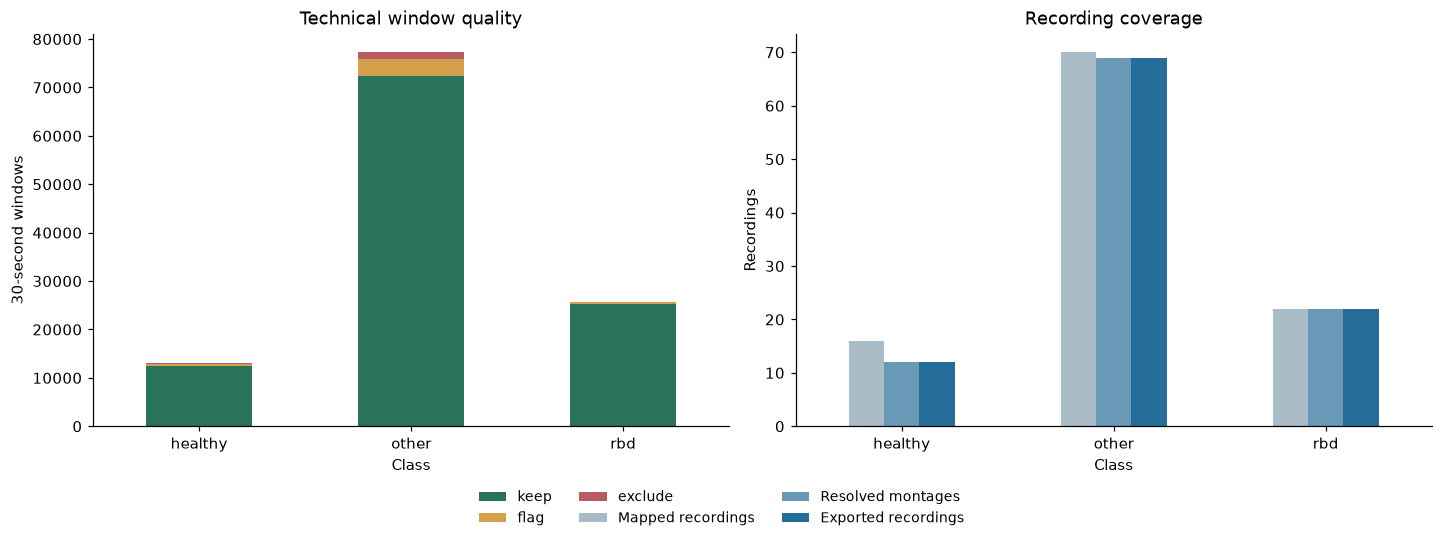

,Mapped recordings,Resolved montages,Exported recordings
class_name,,,
healthy,16,12,12
other,70,69,69
rbd,22,22,22


quality_status,keep,flag,exclude
class_name,,,
healthy,12411,481,200
other,72321,3660,1279
rbd,25255,395,11


,record_id,class_name
0,brux1,other
15,n13,healthy
16,n14,healthy
17,n15,healthy
18,n16,healthy


In [24]:
baseline_windows = window_tables["baseline"]
quality_counts = pd.crosstab(baseline_windows["class_name"], baseline_windows["quality_status"]).reindex(columns=["keep", "flag", "exclude"], fill_value=0)
coverage = pd.DataFrame({
    "Mapped recordings": mapping.groupby("class_name").size(),
    "Resolved montages": inventory[inventory["status"].eq("ready")].groupby("class_name").size(),
    "Exported recordings": recording_tables["baseline"].groupby("class_name").size(),
}).fillna(0).astype(int)
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8), layout="constrained")
quality_counts.plot.bar(stacked=True, ax=axes[0], color=["#28735a", "#d5a04b", "#b85c62"], legend=False, rot=0)
coverage.plot.bar(ax=axes[1], color=["#a9bbc6", "#689ab7", "#246e99"], legend=False, rot=0)
axes[0].set(title="Technical window quality", xlabel="Class", ylabel="30-second windows")
axes[1].set(title="Recording coverage", xlabel="Class", ylabel="Recordings")
handles_left, labels_left = axes[0].get_legend_handles_labels()
handles_right, labels_right = axes[1].get_legend_handles_labels()
fig.legend(handles_left + handles_right, labels_left + labels_right, loc="outside lower center", ncols=3, fontsize=9)
fig.savefig(FIGURE_DIR / "preprocessing_quality_summary.png", bbox_inches="tight", pad_inches=0.18)
plt.show()
display(coverage)
display(quality_counts)
missing_exports = mapping.loc[~mapping["record_id"].isin(recording_tables["baseline"]["record_id"]), ["record_id", "class_name"]]
if not missing_exports.empty:
    display(missing_exports)